In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

### Get data

**Measurements**

In [2]:
g = 9.81 

l = 1.15 
sigma_l = 0.02 

d = 1.15  
sigma_d = 0.002

w = 0.019
sigma_w = 0.001

**Data from computer**

In [3]:
data = pd.read_csv('/home/gea/Desktop/Lab 1/quad_pendolo_2_2025.txt', header=None, delim_whitespace=True,
                   names=["timestamp", "period", "transit"])


In [4]:
data.head()

,timestamp,period,transit
0,2.632223,2.139798,0.011594
1,3.702083,2.139614,0.011634
2,4.771837,2.139390,0.011674
3,5.841473,2.139210,0.011710
4,6.911047,2.139039,0.011746


### Measure speed

In [5]:
import tensorflow as tf

def compute_v0(w, l, d, transit):
    return (w / transit) * (l / d)

def compute_v0_and_uncertainty(w, l, d, transit, sigma_w, sigma_l, sigma_d):

    w = tf.constant(w, dtype=tf.float32)
    l = tf.constant(l, dtype=tf.float32)
    d = tf.constant(d, dtype=tf.float32)
    transit = tf.constant(transit, dtype=tf.float32)

    with tf.GradientTape(persistent=True) as tape:
        tape.watch([w, l, d])
        v0 = compute_v0(w, l, d, transit)

    dv0_dw = tape.gradient(v0, w)
    dv0_dl = tape.gradient(v0, l)
    dv0_dd = tape.gradient(v0, d)

    sigma_v0_squared = (dv0_dw * sigma_w)**2 + (dv0_dl * sigma_l)**2 + (dv0_dd * sigma_d)**2
    sigma_v0 = tf.sqrt(sigma_v0_squared)

    return v0.numpy(), sigma_v0.numpy()

2025-04-02 19:16:17.050197: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-04-02 19:16:17.051159: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-04-02 19:16:17.058720: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-04-02 19:16:17.077747: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-04-02 19:16:17.112685: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been 

In [6]:
v0_results = [compute_v0_and_uncertainty(
    w=w, l=l, d=d, transit=transit_val,
    sigma_w=sigma_w, sigma_l=sigma_l, sigma_d=sigma_d
) for transit_val in data["transit"]]


v0, sigma_v0 = zip(*v0_results)
v0 = np.array(v0)
sigma_v0 = np.array(sigma_v0)

In [7]:
v0

array([1.6387786 , 1.6331443 , 1.6275483 , 1.6225448 , 1.617572  ,
       1.6123556 , 1.607445  , 1.6022937 , 1.5971755 , 1.5920898 ,
       1.5873015 , 1.5828056 , 1.578073  , 1.5731081 , 1.5681742 ,
       1.5632713 , 1.5586545 , 1.5535567 , 1.5487446 , 1.5439622 ,
       1.5394586 , 1.5349814 , 1.53053   , 1.5258592 , 1.5209733 ,
       1.5166028 , 1.5120165 , 1.5074579 , 1.5034024 , 1.499132  ,
       1.4944155 , 1.4897287 , 1.4853033 , 1.480904  , 1.4765309 ,
       1.4721835 , 1.4680883 , 1.4637904 , 1.4592932 , 1.4550467 ,
       1.4510462 , 1.4468473 , 1.4422346 , 1.4380865 , 1.4339622 ,
       1.4298615 , 1.4257841 , 1.4217299 , 1.4174873 , 1.4130596 ,
       1.4088684 , 1.4051175 , 1.4013865 , 1.3972642 , 1.3929619 ,
       1.3888888 , 1.3850416 , 1.3810146 , 1.3770111 , 1.3730308 ,
       1.3690733 , 1.3651386 , 1.3612266 , 1.3573368 , 1.3534691 ,
       1.3496236 , 1.345609  , 1.3419974 , 1.3384051 , 1.334457  ,
       1.3303459 , 1.3264451 , 1.3227513 , 1.3188949 , 1.31524

In [8]:
print(sigma_v0)

[0.09088303 0.09057055 0.09026023 0.08998274 0.08970696 0.08941767
 0.08914533 0.08885966 0.08857581 0.08829377 0.08802822 0.08777889
 0.08751643 0.08724109 0.08696747 0.08669556 0.08643953 0.08615681
 0.08588994 0.08562472 0.08537496 0.08512666 0.0848798  0.08462077
 0.08434981 0.08410742 0.08385308 0.08360027 0.08337536 0.08313854
 0.08287697 0.08261705 0.08237162 0.08212766 0.08188513 0.08164402
 0.08141692 0.08117857 0.08092918 0.08069366 0.0804718  0.08023895
 0.07998314 0.07975309 0.07952437 0.07929695 0.07907082 0.07884599
 0.0786107  0.07836515 0.07813271 0.07792471 0.0777178  0.07748918
 0.07725057 0.0770247  0.07681133 0.07658801 0.07636598 0.07614525
 0.07592577 0.07570756 0.0754906  0.07527488 0.07506039 0.07484712
 0.07462449 0.07442421 0.07422498 0.07400603 0.07377803 0.07356171
 0.07335685 0.07314298 0.07294045 0.07274909 0.07253874 0.07231969
 0.07211181 0.07190513 0.0717094  0.07151472 0.07130179 0.07109012
 0.07090832 0.07070848 0.07049089 0.07028401 0.07008765 0.0698

### Plot speed

In [9]:
def exp_decay(t, v0_0, lambda_):
    return v0_0 * np.exp(-lambda_ * t)

popt, pcov = curve_fit(exp_decay, data["timestamp"], v0, sigma=sigma_v0, p0=[1.6, 0.003])
v0_0_fit, lambda_fit = popt
tau_fit = 1 / lambda_fit

In [10]:
x = v0
y=data["timestamp"]
res = [v0 - exp_decay(timestamp_val, *popt) for timestamp_val in data["timestamp"]]
sigma_y = sigma_v0
x_lim = max(x)+1

res = np.array(res).flatten()

In [11]:
residuals = [v0 - exp_decay(timestamp_val, *popt) for timestamp_val in data["timestamp"]]

In [12]:
plt.figure(figsize=(12,12))
ax1, ax2 = fig.subplots(2, 1, sharex=True, gridspec_kw=dict(height_ratios=[2, 1], hspace=0.05))

ax1.errorbar(data["timestamp"], v0, sigma_v0, fmt='o', label='Data', zorder=1)
ax1.plot(data["timestamp"], exp_decay(data["timestamp"], *popt), label=f"Fit: λ={lambda_fit:.3f}, τ={tau_fit:.3f}", zorder=2)
ax1.legend()

ax2.errorbar(x=data["timestamp"], y=residuals, yerr=sigma_v0, fmt='o')
#ax2.plot(data["timestamp"], np.full(data["timestamp"].shape, 0.0)) # horizontal line at y=0

plt.show()

NameError: name 'fig' is not defined

<Figure size 1200x1200 with 0 Axes>

In [ ]:
# Create the main figure...
fig = plt.figure(figsize=(12, 12))
ax1, ax2 = fig.subplots(2, 1, sharex=True, gridspec_kw=dict(height_ratios=[2, 1], hspace=0.05))

# Main plot: the scatter plot of x vs. y, on the top panel.
ax1.errorbar(x, y, yerr=sigma_y, fmt='o', label='Data')
xgrid = np.linspace(0.0, x_lim, 100)
ax1.plot(xgrid, exp_decay(xgrid, *popt), label='Modello di best-fit')

# And now the residual plot, on the bottom panel.
ax2.errorbar(x, res, sigma_y, fmt='o')
ax2.plot(xgrid, np.full(xgrid.shape, 0.0)) # horizontal line at y=0

# And now the residual plot, on the bottom panel.
ax2.errorbar(x, res, sigma_y, fmt='o')
ax2.plot(xgrid, np.full(xgrid.shape, 0.0)) # horizontal line at y=0


# Styling

ax1.set_ylabel('y [a. u.]')
ax1.grid(color='lightgray', ls='dashed')
ax1.legend()

ax2.set_xlabel('x [a. u.]')
ax2.set_ylabel('Residuals [a. u.]')
ax2.grid(color='lightgray', ls='dashed')

plt.xlim(0.0, x_lim)
fig.align_ylabels((ax1, ax2))

plt.show()

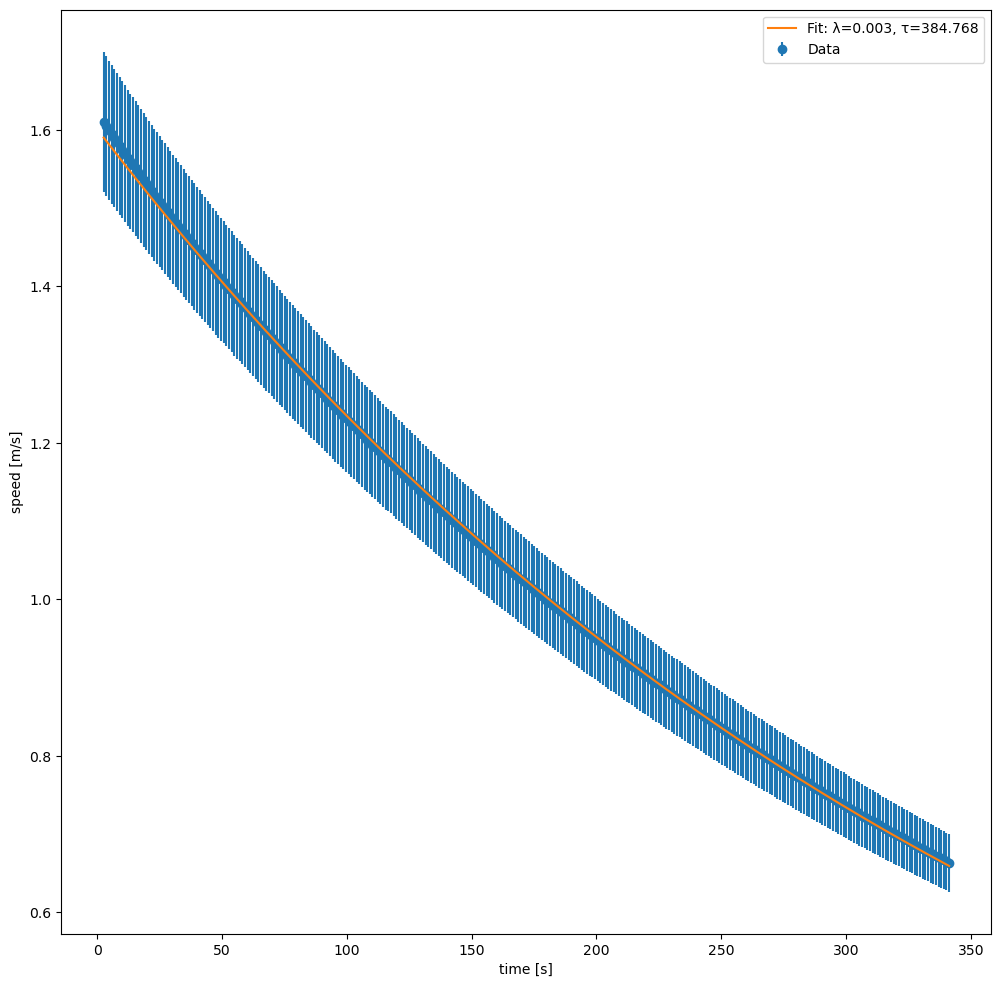

In [478]:
plt.figure(figsize=(12,12))
plt.errorbar(data["timestamp"], v0, sigma_v0, fmt='o', label='Data', zorder=1)
plt.plot(data["timestamp"], exp_decay(data["timestamp"], *popt), label=f"Fit: λ={lambda_fit:.3f}, τ={tau_fit:.3f}", zorder=2)
plt.xlabel("time [s]")
plt.ylabel("speed [m/s]")
plt.legend()
plt.show()

ValueError: 'x' and 'y' must have the same size

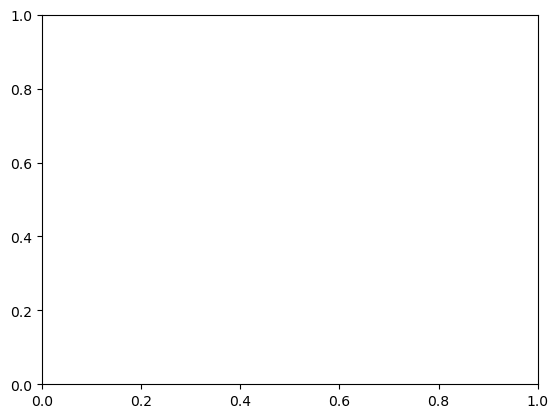

In [513]:
residuals = np.array(residuals).flatten()
sigma_v0 = np.array(sigma_v0).flatten()

plt.errorbar(x=data["timestamp"], y=residuals, yerr=sigma_v0, fmt='o')
plt.show()

**Compute chi square**

In [505]:
residuals = [v0 - exp_decay(timestamp_val, *popt) for timestamp_val in data["timestamp"]]
chi2 = np.sum((residuals / sigma_v0)**2)

dof = len(v0) - len(popt)
chi2_red = chi2 / dof

In [506]:
len(residuals)

320

In [473]:
print(residuals)

[array([ 2.02618837e-02,  1.47255659e-02,  9.22691822e-03,  4.31036949e-03,
       -5.75900078e-04, -5.70154190e-03, -1.05267763e-02, -1.55884027e-02,
       -2.06177235e-02, -2.56149769e-02, -3.03199291e-02, -3.47375870e-02,
       -3.93879414e-02, -4.42664623e-02, -4.91145849e-02, -5.39321899e-02,
       -5.84686995e-02, -6.34778738e-02, -6.82063103e-02, -7.29054213e-02,
       -7.73307085e-02, -8.17301273e-02, -8.61041546e-02, -9.06935930e-02,
       -9.54946280e-02, -9.97891426e-02, -1.04295611e-01, -1.08775020e-01,
       -1.12759948e-01, -1.16955996e-01, -1.21590495e-01, -1.26195788e-01,
       -1.30544305e-01, -1.34867072e-01, -1.39164090e-01, -1.43435955e-01,
       -1.47459865e-01, -1.51682973e-01, -1.56101942e-01, -1.60274744e-01,
       -1.64205551e-01, -1.68331385e-01, -1.72863841e-01, -1.76939845e-01,
       -1.80992484e-01, -1.85021758e-01, -1.89028382e-01, -1.93011999e-01,
       -1.97180867e-01, -2.01531529e-01, -2.05649853e-01, -2.09335446e-01,
       -2.13001609e-01, 

In [474]:
print(chi2_red)

16093.127358490567


### Measure theta

In [475]:
theta0= np.arccos(1 - v0**2 / (2 * g * l))

In [476]:
T0 = 2 * np.pi * np.sqrt(l/g) + (theta0 * 0)
T2 = T0 * (1+theta0**2/16)
T4 = T0 * (1+theta0**2/16 + theta0**4/3072)

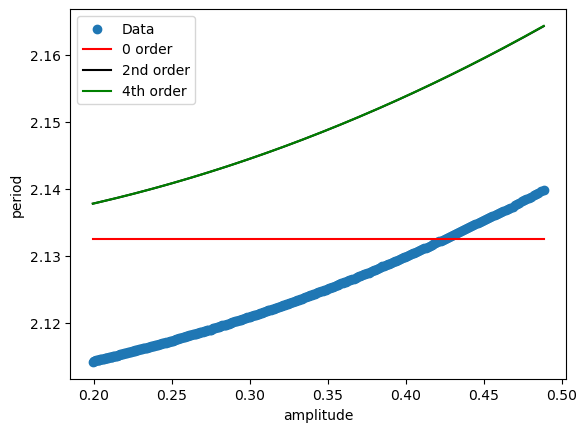

In [477]:
plt.figure()

plt.scatter(theta0, data["period"], label="Data")
plt.plot(theta0, T0, 'red', label='0 order')
plt.plot(theta0, T2, 'black', zorder=1, label='2nd order')
plt.plot(theta0, T4, 'green', zorder=2, label='4th order')


plt.xlabel("amplitude")
plt.ylabel("period")
plt.legend()
plt.show()
